# Feature Importance

In [5]:
import sys
from pathlib import Path
_root = Path.cwd().parent  # Setting root
sys.path.append(str(_root / "jointCode"))
sys.path.append(str(_root / "classicalCode"))
from sklearn.ensemble import RandomForestClassifier
from data_loader import HLS4ML_DataLoader, LHCOlympics_DataLoader
from c_config import CONFIG
import numpy as np
from utils import createRunDir, saveUsefulInfo, createSubRNGS

# Check all features for all data
CONFIG["data"]["LHCOlympics_features"] = ["pxj1","pyj1","pzj1","mj1","tau1j1","tau2j1","tau3j1","pxj2","pyj2","pzj2","mj2","tau1j2","tau2j2","tau3j2"]
CONFIG["circuit"]["encoder_shape"] = [14,1]
CONFIG["data"]["final_val_num_samples"] = 220000

# Delete useless path after
run_path = createRunDir(CONFIG)
infoSave = saveUsefulInfo(run_path)
rngs = createSubRNGS(CONFIG)

dataloader = LHCOlympics_DataLoader(CONFIG, rngs, infoSave, "classical")
X_train, X_val, y_val = dataloader.loadTrainValArrays()

print(X_train.shape)

def featureImportance(X, y):

    # Train a RandomForestClassifier
    clf = RandomForestClassifier(n_estimators=100)
    clf.fit(X, y)

    # Get feature importances
    importances = clf.feature_importances_

    # Sort indices by importance descending
    idx_sorted = np.argsort(importances)[::-1]

    return [(CONFIG["data"]["LHCOlympics_features"][int(i)], importances[int(i)]) for i in idx_sorted]

featureImportance(X_val,y_val)

- Run Directory Created: /home/hep/lgc124/PhDCode/LXAutoQML/AutoQML/outputs/2026-05-11/10-26-54:(4c743):C:
- Data Loaded: 5000 Training + 220000 Validation Jets.
- Encoding 14 features.
(5000, 14)


[('mj1', 0.16994316485217906),
 ('mj2', 0.14471207986129836),
 ('tau1j1', 0.12732663292109211),
 ('tau1j2', 0.11580817838376486),
 ('tau3j2', 0.07300630577841444),
 ('tau3j1', 0.07023395452845016),
 ('pxj2', 0.04817355704275796),
 ('tau2j1', 0.04792555001778584),
 ('pyj2', 0.04554303313602388),
 ('tau2j2', 0.042692734563368286),
 ('pyj1', 0.03644700100815119),
 ('pxj1', 0.035715748481254146),
 ('pzj2', 0.021336236970741256),
 ('pzj1', 0.021135822454718393)]

In [ ]:
import numpy as np
import strawberryfields as sf
from strawberryfields.ops import *
from strawberryfields.utils import samples_expectation, samples_variance
import matplotlib.pyplot as plt

expectations = []

test_range = np.arange(-1.5,1.6,0.1)
#test_range = [0.9,1,1.1]
for i in test_range:

    prog = sf.Program(2)
    with prog.context as q:

        Sgate(1, 0.0) | q[0]
        Sgate(i, 0.0) | q[1]
        BSgate(np.pi/4,0).H | (q[0],q[1])
        MeasureFock() | q

    # Run the program using the Fock backend
    eng = sf.Engine("fock", backend_options={"cutoff_dim": 5})
    results = eng.run(prog, shots=500)

    exp = samples_expectation(results.samples)
    var = samples_variance(results.samples)
    std = np.sqrt(var)
    stderr = std/np.sqrt(len(results.samples))
    expectations.append((exp,stderr))

    print(f"Finished {i}")

with open('BS-Fid.txt', 'w') as f:
    for e in expectations:
        f.write(f"{e}\n")

plt.figure()
plt.errorbar(test_range, [i[0] for i in expectations], yerr = [i[1] for i in expectations], fmt="mo",capsize=3)
plt.ylabel("Total Photon Number \n Expectation Value")
plt.xlabel("Qubit 2 Squeeze Parameter")
#plt.savefig("BS-Fid.png",dpi=300,bbox_inches="tight")

/home/hep/lgc124/conda_envs/AutoQMLEnv/lib/python3.10/site-packages/strawberryfields/backends/gaussianbackend/backend.py:216: UserWarning: Cannot simulate non-Gaussian states. Conditional state after Fock measurement has not been updated.


Finished -1.5
Finished -1.4
Finished -1.2999999999999998
Finished -1.1999999999999997
Finished -1.0999999999999996
Finished -0.9999999999999996
Finished -0.8999999999999995
Finished -0.7999999999999994
Finished -0.6999999999999993
Finished -0.5999999999999992
Finished -0.4999999999999991
Finished -0.399999999999999
Finished -0.29999999999999893
Finished -0.19999999999999885
Finished -0.09999999999999876
Finished 1.3322676295501878e-15
Finished 0.10000000000000142
Finished 0.2000000000000015
Finished 0.3000000000000016
Finished 0.4000000000000017
Finished 0.5000000000000018
Finished 0.6000000000000019


Finished 1 vs 0.5
Finished 1 vs 0.6
Finished 1 vs 0.7
Finished 1 vs 0.7999999999999999
Finished 1 vs 0.8999999999999999
Finished 1 vs 0.9999999999999999
Finished 1 vs 1.0999999999999999
Finished 1 vs 1.1999999999999997
Finished 1 vs 1.2999999999999998
Finished 1 vs 1.4
Finished 1 vs 1.4999999999999998


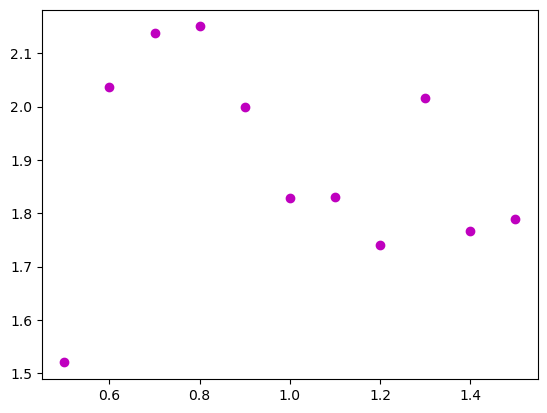

In [58]:
import numpy as np
import strawberryfields as sf
from strawberryfields.ops import Sgate, MeasureHomodyne
import matplotlib.pyplot as plt

shots = int(1e2)  # number of repetitions
comparison_val = np.arange(0.5,1.6,0.1)

F_list = []
for i in comparison_val:
    x1_list, y1_list = [], []
    x2_list, y2_list = [], []

    eng = sf.Engine("gaussian")  # Gaussian backend

    for _ in range(shots):
        # --- Circuit 1 ---
        prog_1x = sf.Program(1)
        with prog_1x.context as q:
            Sgate(1.0) | q
            MeasureHomodyne(phi=0) | q
        x1 = eng.run(prog_1x).samples[0,0]

        prog_1y = sf.Program(1)
        with prog_1y.context as q:
            Sgate(1.0) | q
            MeasureHomodyne(phi=np.pi/2) | q
        y1 = eng.run(prog_1y).samples[0,0]

        x1_list.append(x1)
        y1_list.append(y1)

        # --- Circuit 2 ---
        prog_2x = sf.Program(1)
        with prog_2x.context as q:
            Sgate(i) | q
            MeasureHomodyne(phi=0) | q
        x2 = eng.run(prog_2x).samples[0,0]

        prog_2y = sf.Program(1)
        with prog_2y.context as q:
            Sgate(i) | q
            MeasureHomodyne(phi=np.pi/2) | q
        y2 = eng.run(prog_2y).samples[0,0]

        x2_list.append(x2)
        y2_list.append(y2)

    # --- Build arrays ---
    samples1 = np.stack([x1_list, y1_list], axis=1)  # shape (shots,2)
    samples2 = np.stack([x2_list, y2_list], axis=1)

    # --- Compute mean amplitudes ---
    alpha_x1 = np.mean(x1_list)
    alpha_y1 = np.mean(y1_list)
    alpha_x2 = np.mean(x2_list)
    alpha_y2 = np.mean(y2_list)

    # --- Compute covariance matrices ---
    V1 = np.cov(samples1.T, bias=True)
    V2 = np.cov(samples2.T, bias=True)

    # --- Calculating fidelity elements (https://journals.aps.org/pra/abstract/10.1103/PhysRevA.71.032336)
    Delta = np.linalg.det(V1+V2)
    delta = (np.linalg.det(V1)-1)*(np.linalg.det(V2)-1)
    delta = max(delta, 0.0) # shouldn't be below 0, noise/finite effects
    alpha_1 = np.array([alpha_x1, alpha_y1])
    alpha_2 = np.array([alpha_x2, alpha_y2])
    beta = alpha_2 - alpha_1

    F = np.sqrt(2 / (np.sqrt(Delta+delta) - np.sqrt(delta)) )*np.exp(-beta.T @ np.linalg.inv(V1+V2) @ beta)
    F_list.append(F)
    print(f"Finished 1 vs {i}")

plt.figure()
plt.plot(comparison_val,F_list, "mo")
#plt.savefig("Homodyne-Fid.png", dpi=300, bbox_inches="tight")

# BS Hilbert-Schmidt Overlap by Averaging Parity

Finished 0.5
Finished 0.55
Finished 0.6000000000000001
Finished 0.6500000000000001
Finished 0.7000000000000002
Finished 0.7500000000000002
Finished 0.8000000000000003
Finished 0.8500000000000003
Finished 0.9000000000000004
Finished 0.9500000000000004
Finished 1.0000000000000004
Finished 1.0500000000000005
Finished 1.1000000000000005
Finished 1.1500000000000006
Finished 1.2000000000000006
Finished 1.2500000000000007
Finished 1.3000000000000007
Finished 1.3500000000000008
Finished 1.4000000000000008
Finished 1.4500000000000008
Finished 1.5000000000000009
Finished 1.550000000000001


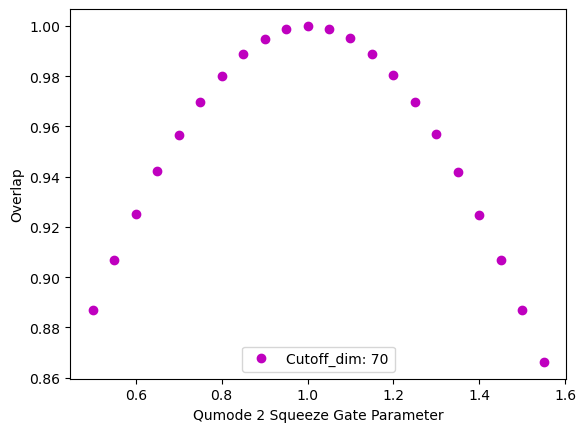

In [14]:
import numpy as np
import strawberryfields as sf
from strawberryfields.ops import *
from strawberryfields.utils import samples_expectation, samples_variance
import matplotlib.pyplot as plt

cutoff_dim = 70
overlaps = []

test_range = np.arange(0.5,1.6,0.05)

for i in test_range:

    prog = sf.Program(2)
    with prog.context as q:

        Sgate(1, 0.0) | q[0]
        Sgate(i, 0.0) | q[1]
        BSgate(np.pi/4,0).H | (q[0],q[1])

    # Run the program using the Fock backend (statevector simulator)
    eng = sf.Engine("fock", backend_options={"cutoff_dim": cutoff_dim})
    result = eng.run(prog)
    probs = result.state.all_fock_probs()

    # Sampling shots (from statevector probs)
    num_shots = int(1e6)
    
    # Flatten and normalise probabilities before sampling from them
    flat_probs = probs.flatten()
    flat_probs = flat_probs / flat_probs.sum()
    
    # Sample indices according to probs
    indices = np.arange(flat_probs.size)
    sampled_indices = np.random.choice(indices, size=num_shots, p=flat_probs)

    # Convert samples back to n,m (for photon-mode clarity per shot)
    n_samples = sampled_indices // probs.shape[1]
    m_samples = sampled_indices % probs.shape[1]

    # Define Heaviside step function
    def heaviside(x):
        return (x >= 0).astype(float)

    # Calculate average
    values = (-1)**n_samples * heaviside(2*cutoff_dim - n_samples - m_samples)
    overlap = np.mean(values)

    overlaps.append(overlap)
    print(f"Finished {i}")

plt.figure()
plt.plot(test_range, overlaps, "mo",label=f"Cutoff_dim: {cutoff_dim}")
plt.ylabel("Overlap")
plt.xlabel("Qumode 2 Squeeze Gate Parameter")
plt.legend(loc="lower center")
#plt.savefig(f"FidelityInvPlots/PNR-HSO-{cutoff_dim}.png",dpi=300,bbox_inches="tight")

#### Trying the same, but with TF backend

Finished 0.5
Finished 0.55
Finished 0.6000000000000001
Finished 0.6500000000000001
Finished 0.7000000000000002
Finished 0.7500000000000002
Finished 0.8000000000000003
Finished 0.8500000000000003
Finished 0.9000000000000004
Finished 0.9500000000000004
Finished 1.0000000000000004
Finished 1.0500000000000005
Finished 1.1000000000000005
Finished 1.1500000000000006
Finished 1.2000000000000006
Finished 1.2500000000000007
Finished 1.3000000000000007
Finished 1.3500000000000008
Finished 1.4000000000000008
Finished 1.4500000000000008
Finished 1.5000000000000009
Finished 1.550000000000001


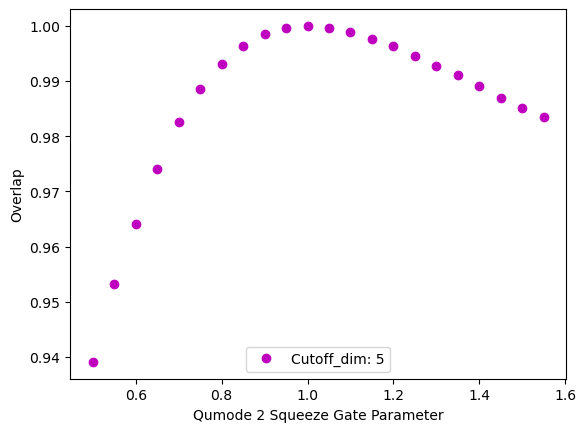

In [8]:
import numpy as np
import strawberryfields as sf
from strawberryfields.ops import *
from strawberryfields.utils import samples_expectation, samples_variance
import matplotlib.pyplot as plt

cutoff_dim = 5
overlaps = []

test_range = np.arange(0.5,1.6,0.05)

for i in test_range:

    prog = sf.Program(2)
    with prog.context as q:

        Sgate(1, 0.0) | q[0]
        Sgate(i, 0.0) | q[1]
        BSgate(np.pi/4,0).H | (q[0],q[1])

    # Run the program using the TF backend (statevector simulator)
    eng = sf.Engine("tf", backend_options={"cutoff_dim": cutoff_dim})
    result = eng.run(prog)
    probs = result.state.all_fock_probs().numpy()

    # Sampling shots (from statevector probs)
    num_shots = int(1e6)
    
    # Flatten and normalise probabilities before sampling from them
    flat_probs = probs.flatten()
    flat_probs = flat_probs / flat_probs.sum()
    
    # Sample indices according to probs
    indices = np.arange(flat_probs.size)
    sampled_indices = np.random.choice(indices, size=num_shots, p=flat_probs)

    # Convert samples back to n,m (for photon-mode clarity per shot)
    n_samples = sampled_indices // probs.shape[1]
    m_samples = sampled_indices % probs.shape[1]

    # Define Heaviside step function
    def heaviside(x):
        return (x >= 0).astype(float)

    # Calculate average
    values = (-1)**n_samples * heaviside(2*cutoff_dim - n_samples - m_samples)
    overlap = np.mean(values)

    overlaps.append(overlap)
    print(f"Finished {i}")

plt.figure()
plt.plot(test_range, overlaps, "mo",label=f"Cutoff_dim: {cutoff_dim}")
plt.ylabel("Overlap")
plt.xlabel("Qumode 2 Squeeze Gate Parameter")
plt.legend(loc="lower center")
#plt.savefig(f"FidelityInvPlots/PNR-HSO-{cutoff_dim}.png",dpi=300,bbox_inches="tight")

#### The same but without shots = exact

Finished 0.5
Finished 0.55
Finished 0.6000000000000001
Finished 0.6500000000000001
Finished 0.7000000000000002
Finished 0.7500000000000002
Finished 0.8000000000000003
Finished 0.8500000000000003
Finished 0.9000000000000004
Finished 0.9500000000000004
Finished 1.0000000000000004
Finished 1.0500000000000005
Finished 1.1000000000000005
Finished 1.1500000000000006
Finished 1.2000000000000006
Finished 1.2500000000000007
Finished 1.3000000000000007
Finished 1.3500000000000008
Finished 1.4000000000000008
Finished 1.4500000000000008
Finished 1.5000000000000009
Finished 1.550000000000001


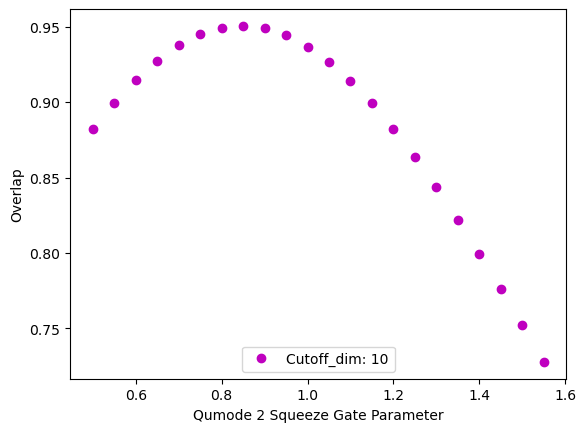

In [5]:
import numpy as np
import strawberryfields as sf
from strawberryfields.ops import *
import matplotlib.pyplot as plt

cutoff_dim = 10
overlaps = []

test_range = np.arange(0.5,1.6,0.05)

for i in test_range:

    prog = sf.Program(2)
    with prog.context as q:
        Sgate(1, 0.0) | q[0]
        Sgate(i, 0.0) | q[1]
        BSgate(np.pi/4,0).H | (q[0],q[1])

    eng = sf.Engine("tf", backend_options={"cutoff_dim": cutoff_dim})
    result = eng.run(prog)
    probs = result.state.all_fock_probs().numpy()  # shape: (cutoff, cutoff)

    # Fock indices
    n = np.arange(cutoff_dim)[:, None]
    m = np.arange(cutoff_dim)[None, :]

    # Heaviside + parity operator
    values = (-1)**n * (2*cutoff_dim - n - m >= 0)

    # Exact expectation value (overlap)
    overlap = np.sum(values * probs)

    overlaps.append(overlap)
    print(f"Finished {i}")

plt.figure()
plt.plot(test_range, overlaps, "mo", label=f"Cutoff_dim: {cutoff_dim}")
plt.ylabel("Overlap")
plt.xlabel("Qumode 2 Squeeze Gate Parameter")
plt.legend(loc="lower center")
plt.show()

# General BS Test

In [4]:
import numpy as np
import strawberryfields as sf
from strawberryfields.ops import *
from strawberryfields.utils import samples_expectation, samples_variance
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

def plot(theta, squeeze_q1):

    cutoff_dim = 10

    prog = sf.Program(2)
    with prog.context as q:

        Sgate(1, 0.0) | q[0]
        Sgate(squeeze_q1, 0.0) | q[1]
        BSgate(theta) | (q[0],q[1]) # 50/50

    # 2. Run engine
    eng = sf.Engine("fock", backend_options={"cutoff_dim":cutoff_dim})
    result = eng.run(prog)
    state = result.state

    # recompute Strawberry Fields program
    probs = state.all_fock_probs()

    n = np.arange(probs.shape[0])
    X, Y = np.meshgrid(n, n)
    
    plt.figure()
    plt.imshow(probs, origin="lower")
    plt.title("Photon Number Probability")
    plt.ylabel("n (q0, s=1)")
    plt.xlabel("n (q1)")
    plt.colorbar()

widgets.interact(plot, theta=(0, np.pi/4, np.pi/128), squeeze_q1=(0,1.5,0.1))

interactive(children=(FloatSlider(value=0.39269908169872414, description='theta', max=0.7853981633974483, step…

<function __main__.plot(theta, squeeze_q1)>

### Simon's displacement request

In [12]:
import numpy as np
import strawberryfields as sf
from strawberryfields.ops import *
from strawberryfields.utils import samples_expectation, samples_variance
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

def plot(theta, disp_q1):

    cutoff_dim = 10

    prog = sf.Program(2)
    with prog.context as q:

        Fock(3) | q[0]
        Dgate(disp_q1, 0.0) | q[1]
        BSgate(theta) | (q[0],q[1]) # 50/50

    # 2. Run engine
    eng = sf.Engine("fock", backend_options={"cutoff_dim":cutoff_dim})
    result = eng.run(prog)
    state = result.state

    # recompute Strawberry Fields program
    probs = state.all_fock_probs()

    n = np.arange(probs.shape[0])
    X, Y = np.meshgrid(n, n)
    
    plt.figure()
    plt.imshow(probs, origin="lower")
    plt.title("Photon Number Probability")
    plt.ylabel("n (q0)")
    plt.xlabel("n (q1)")
    plt.colorbar()

    # OVERLAP 
    # Sampling shots (from statevector probs)
    num_shots = int(1e6)
    
    # Flatten and normalise probabilities before sampling from them
    flat_probs = probs.flatten()
    flat_probs = flat_probs / flat_probs.sum()
    
    # Sample indices according to probs
    indices = np.arange(flat_probs.size)
    sampled_indices = np.random.choice(indices, size=num_shots, p=flat_probs)

    # Convert samples back to n,m (for photon-mode clarity per shot)
    n_samples = sampled_indices // probs.shape[1]
    m_samples = sampled_indices % probs.shape[1]

    # Define Heaviside step function
    def heaviside(x):
        return (x >= 0).astype(float)

    # Calculate average
    values = (-1)**n_samples * heaviside(2*cutoff_dim - n_samples - m_samples)
    overlap = np.mean(values)

    print(f"Overlap: {overlap}")

widgets.interact(plot, theta=(0, np.pi/4, np.pi/128), disp_q1=(0,3,0.1))

interactive(children=(FloatSlider(value=0.39269908169872414, description='theta', max=0.7853981633974483, step…

<function __main__.plot(theta, disp_q1)>

# Homodyne Experimentation

#### 2-Qumode Initial Testing

In [20]:
import numpy as np
import strawberryfields as sf
from strawberryfields.ops import Sgate, MeasureHomodyne, Dgate, BSgate
import matplotlib.pyplot as plt
import tensorflow as tf
import ipywidgets as widgets
tf.get_logger().setLevel('ERROR')

sf.hbar = 1 # more standard!

###########################################

# shots = int(5e2)  # number of repetitions
# eng = sf.Engine("tf", backend_options={"cutoff_dim": 6})

# results = []
# for _ in range(shots):
#     # --- Circuit 1 ---
#     prog_1x = sf.Program(2)
#     with prog_1x.context as q:
#         Dgate(1.0) | q
#         MeasureHomodyne(phi=0) | q
#     x1 = eng.run(prog_1x).samples[0,0]
#     results.append(x1)

# plt.figure()
# plt.hist(results,bins=30)

###########################################

def wigner(param1,param2):
    eng = sf.Engine("gaussian")

    prog = sf.Program(2)
    with prog.context as q:
        Dgate(param1, 0)   | q[0]
        Dgate(param2, 0) | q[1]
        BSgate(np.pi/4, phi=np.pi/2) | (q[0],q[1])

    result = eng.run(prog)
    state = result.state

    # phase space grid
    x = np.linspace(-5,5,200)
    p = np.linspace(-5,5,200)

    W = state.wigner(0, x, p)

    # Plot Wigner
    plt.figure()
    plt.contourf(x, p, W, 100)

    means = state.means()
    mx, mp = means[0], means[2]   # Mean lines (for clarity)
    plt.axvline(mx,ls="--",label="Mean")
    plt.axhline(mp,ls="--")

    plt.xlabel("x")
    plt.ylabel("p")
    plt.title("Wigner Function of q0")
    plt.colorbar()
    plt.legend(loc="upper left")
    

widgets.interact(wigner, param1=(0, 2, 0.05), param2=(0,2,0.05))

interactive(children=(FloatSlider(value=1.0, description='param1', max=2.0, step=0.05), FloatSlider(value=1.0,…

<function __main__.wigner(param1, param2)>

#### CVQC Operation Investigations (disp,squeeze,rot,BS)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
import strawberryfields as sf
from strawberryfields.ops import Dgate, Sgate, Rgate, BSgate

def plot_phase_space(means, cov, label='Mode', color='blue'):
    """Plot ellipse for a single mode in x-p plane."""
    from matplotlib.patches import Ellipse
    # Eigen-decomposition for ellipse
    vals, vecs = np.linalg.eigh(cov)
    angle = np.degrees(np.arctan2(*vecs[:,0][::-1]))
    width, height = 2*np.sqrt(vals)
    ellipse = Ellipse(xy=means, width=width, height=height, angle=angle,
                      edgecolor=color, facecolor='none', lw=2, label=label)
    fig, ax = plt.subplots(figsize=(5,5))
    ax.add_patch(ellipse)
    ax.plot(means[0], means[1], 'o', color=color)
    ax.set_xlabel('x')
    ax.set_ylabel('p')
    ax.set_xlim(-5,5)
    ax.set_ylim(-5,5)
    ax.set_title(label)
    ax.grid(True)
    plt.show()

# 1. Single-mode displacement
def single_displacement(alpha):
    eng = sf.Engine("gaussian")
    prog = sf.Program(1)
    with prog.context as q:
        Dgate(alpha, 0) | q[0]
    state = eng.run(prog).state
    means = state.means()[[0,1]]
    cov = state.cov()[np.ix_([0,1],[0,1])]
    plot_phase_space(means, cov, label=f'Single-mode Displacement α={alpha}')

# 2. Single-mode squeeze
def single_squeeze(r):
    eng = sf.Engine("gaussian")
    prog = sf.Program(1)
    with prog.context as q:
        Sgate(r) | q[0]
    state = eng.run(prog).state
    means = state.means()[[0,1]]
    cov = state.cov()[np.ix_([0,1],[0,1])]
    plot_phase_space(means, cov, label=f'Single-mode squeezing r={r}')

# 3. Single-mode rotation (with displacement & squeeze)
def single_rotation(alpha, r, phi):
    eng = sf.Engine("gaussian")
    prog = sf.Program(1)
    with prog.context as q:
        Dgate(alpha, 0) | q[0]
        Sgate(r) | q[0]
        Rgate(phi) | q[0]
    state = eng.run(prog).state
    means = state.means()[[0,1]]
    cov = state.cov()[np.ix_([0,1],[0,1])]
    plot_phase_space(means, cov, label=f'Rotation φ={phi:.2f}')

# 4. Two-mode BS (first displaced & squeezed, second vacuum)
def two_mode_bs(alpha, r, bs):
    eng = sf.Engine("gaussian")
    prog = sf.Program(2)
    with prog.context as q:
        Dgate(alpha,0) | q[0]
        Sgate(r) | q[0]
        # second mode is vacuum
        BSgate(bs) | (q[0], q[1])
    state = eng.run(prog).state
    # Mode 0
    means0 = state.means()[[0,2]]
    cov0 = state.cov()[np.ix_([0,2],[0,2])]
    # Mode 1
    means1 = state.means()[[1,3]]
    cov1 = state.cov()[np.ix_([1,3],[1,3])]
    # Plot both
    fig, ax = plt.subplots(figsize=(5,5))
    from matplotlib.patches import Ellipse
    for means, cov, color, lbl in zip([means0, means1],[cov0,cov1],['blue','red'],['Mode 0','Mode 1 (vac)']):
        vals, vecs = np.linalg.eigh(cov)
        angle = np.degrees(np.arctan2(*vecs[:,0][::-1]))
        width, height = 2*np.sqrt(vals)
        ellipse = Ellipse(xy=means, width=width, height=height, angle=angle,
                          edgecolor=color, facecolor='none', lw=2, label=lbl)
        ax.add_patch(ellipse)
        ax.plot(means[0], means[1], 'o', color=color)
    ax.set_xlim(-5,5)
    ax.set_ylim(-5,5)
    ax.set_xlabel('x')
    ax.set_ylabel('p')
    ax.set_title(f'2-mode BS, bs={np.round(bs,2)}')
    ax.grid(True)
    ax.legend()
    plt.show()

# Widgets
widgets.interact(single_displacement, alpha=(0,3,0.1))
widgets.interact(single_squeeze, r=(0,2,0.05))
widgets.interact(single_rotation, alpha=(0,2,0.1), r=(0,2,0.05), phi=(0,2*np.pi,0.05))
widgets.interact(two_mode_bs, alpha=(0,2,0.1), r=(0,2,0.05), bs=(0,np.pi/4,0.05))

/home/hep/lgc124/conda_envs/AutoQMLEnv/lib/python3.10/site-packages/strawberryfields/apps/data/sample.py:20: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
2026-03-25 13:19:01.051091: I tensorflow/core/util/port.cc:110] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-03-25 13:19:01.053373: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-03-25 13:19:01.099562: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-03-25 13:19:01.100576: I tensorflow/core/platform/cpu_f

interactive(children=(FloatSlider(value=1.0, description='alpha', max=3.0), Output()), _dom_classes=('widget-i…

interactive(children=(FloatSlider(value=1.0, description='r', max=2.0, step=0.05), Output()), _dom_classes=('w…

interactive(children=(FloatSlider(value=1.0, description='alpha', max=2.0), FloatSlider(value=1.0, description…

interactive(children=(FloatSlider(value=1.0, description='alpha', max=2.0), FloatSlider(value=1.0, description…

<function __main__.two_mode_bs(alpha, r, bs)>

#### Overlap Estimator (old)

In [2]:
sf.hbar = 1 # more standard!
def two_mode_pre_post_bs(alpha, r):
    fig, axes = plt.subplots(1, 2, figsize=(10,5))

    for ax, bs, title in zip(
        axes,
        [0, np.pi/4],
        ["Pre-BS (bs=0)", "Post-BS (bs=π/4)"]
    ):
        eng = sf.Engine("gaussian")
        prog = sf.Program(2)

        with prog.context as q:
            
            Dgate(alpha,0) | q[0]
            Sgate(r) | q[0]                        
            
            BSgate(bs) | (q[0], q[1])

        state = eng.run(prog).state

        means0 = state.means()[[0,2]]
        cov0   = state.cov()[np.ix_([0,2],[0,2])]
        means1 = state.means()[[1,3]]
        cov1   = state.cov()[np.ix_([1,3],[1,3])]

        from matplotlib.patches import Ellipse

        for means, cov, color in zip(
            [means0, means1],
            [cov0, cov1],
            ['blue','red']
        ):
            vals, vecs = np.linalg.eigh(cov)
            angle = np.degrees(np.arctan2(*vecs[:,0][::-1]))
            width, height = 2*np.sqrt(vals)

            ellipse = Ellipse(
                xy=means, width=width, height=height, angle=angle,
                edgecolor=color, facecolor='none', lw=2
            )
            ax.add_patch(ellipse)
            ax.plot(means[0], means[1], 'o', color=color)

        ax.set_xlim(-5,5)
        ax.set_ylim(-5,5)
        ax.set_xlabel('x')
        ax.set_ylabel('p')
        ax.set_title(title)
        ax.grid(True)

        ###### Simulated Measurements After BS / Circuit ######
        if bs == np.pi/4:
            ############################ Displacement
            x0,_ = means0[0],means0[1]  # Mimic x homodyne on 0 (post-BS measurement result)
            _,p1 = means1[0],means1[1]  # and p homodyne on 1   (post-BS measurement result)

            # We can then use the p1 (post) info to give us the p0_pre (as they are the same post BS, and we know how they transform)
            pre_BS_x0 = x0*np.sqrt(2)   # Pre-BS position
            pre_BS_p0 = p1*np.sqrt(2)   # Pre-BS position

            r2 = (pre_BS_x0)**2 + (pre_BS_p0)**2
            metric1 = 1 / (1+r2)
            ############################ Variance/Squeezing
            x0_var = cov0[0,0]  # Mimic x homodyne on 0
            p1_var = cov1[1,1]  # and p homodyne on 1

            # We can then use the p1_var (post) info to give us the p0_var_pre (as they are the same post BS, and we know how they transform)
            pre_BS_x0_var = 2*x0_var - 0.5 # as v_out = 1/2 (V_q + V_vac=1/2), rearrange for V_q
            pre_BS_p0_var = 2*p1_var - 0.5

            r2_var = (pre_BS_x0_var - 0.5)**2 + (pre_BS_p0_var - 0.5)**2
            metric2 = 1 / (1 + r2_var)
            ############################ Overlap
            overlap = metric1*metric2
            ############################ Print
            print("POST:")
            print(f"x0 = x1 = {x0}, p0 = p1 = {p1}")
            print(f"x0_var = x1_var = {x0_var}, p0_var = p1_var = {p1_var}\n")

            print("PRE (from post-measurements):")
            print(f"x0 = {pre_BS_x0}, p0 = {pre_BS_p0}")
            print(f"x0_var = {pre_BS_x0_var}, p0_var = {pre_BS_p0_var}\n")

            print("OVERLAP:")
            print(f"metric_disp = {metric1}, metric_var = {metric2}")
            print(f"overlap = {overlap}\n")

            print("EXTRA:")
            print(f"Covariances: {cov0[0,1]}, {cov0[1,0]}, {cov1[0,1]}, {cov1[1,0]}")

            # This works for D then S (not S then D)
            r = -0.25 * np.log(pre_BS_x0_var / pre_BS_p0_var)
            # alpha = (pre_BS_x0 + 1j * pre_BS_p0) / np.sqrt(2)
            alpha_real = pre_BS_x0 / (np.sqrt(2) * np.exp(-r))
            alpha_imag = pre_BS_p0 / (np.sqrt(2) * np.exp(r))
            alpha = alpha_real + 1j*alpha_imag
            #print((r,alpha))

            ############################

    plt.tight_layout()
    plt.show()

widgets.interact(two_mode_pre_post_bs, alpha=(-2,2,0.1), r=(-2,2,0.05))

interactive(children=(FloatSlider(value=0.0, description='alpha', max=2.0, min=-2.0), FloatSlider(value=0.0, d…

<function __main__.two_mode_pre_post_bs(alpha, r)>

#### Overlap Parameter Space (new method)

/home/hep/lgc124/conda_envs/AutoQMLEnv/lib/python3.10/site-packages/strawberryfields/apps/data/sample.py:20: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
2026-03-30 11:17:10.652967: I tensorflow/core/util/port.cc:110] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-03-30 11:17:10.655294: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-03-30 11:17:10.700018: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-03-30 11:17:10.700975: I tensorflow/core/platform/cpu_f

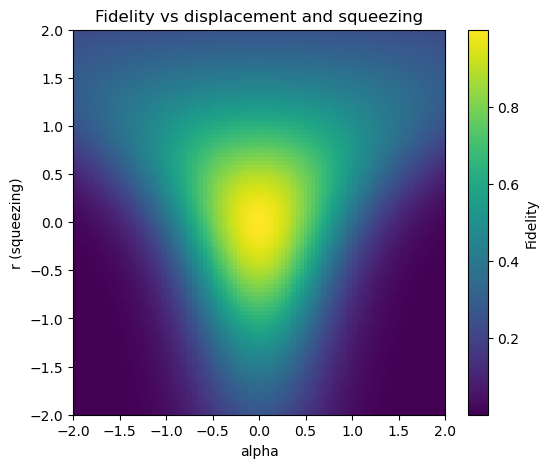

In [1]:
import numpy as np
import strawberryfields as sf
from strawberryfields.ops import Sgate, MeasureHomodyne, Dgate, BSgate
import matplotlib.pyplot as plt
import tensorflow as tf
import ipywidgets as widgets

sf.hbar = 1 # more standard!
def overlap_map(alpha_range, r_range, res=50):
    alphas = np.linspace(*alpha_range, res)
    rs = np.linspace(*r_range, res)

    overlap_grid = np.zeros((res, res))

    for i, a in enumerate(alphas):
        for j, r in enumerate(rs):
            eng = sf.Engine("gaussian")
            prog = sf.Program(2)

            with prog.context as q:
                
                Dgate(a,0) | q[0]
                Sgate(r) | q[0]
                            
                BSgate(np.pi/4) | (q[0], q[1])

            state = eng.run(prog).state
            means0 = state.means()[[0,2]]
            cov0   = state.cov()[np.ix_([0,2],[0,2])]
            means1 = state.means()[[1,3]]
            cov1   = state.cov()[np.ix_([1,3],[1,3])]

            ############################ Displacement
            x0,_ = means0[0],means0[1]  # Mimic x homodyne on 0 (post-BS measurement result)
            _,p1 = means1[0],means1[1]  # and p homodyne on 1   (post-BS measurement result)

            # We can then use the p1 (post) info to give us the p0_pre (as they are the same post BS, and we know how they transform)
            pre_BS_x0 = x0*np.sqrt(2)   # Pre-BS position
            pre_BS_p0 = p1*np.sqrt(2)   # Pre-BS position

            r2 = (pre_BS_x0)**2 + (pre_BS_p0)**2
            metric1 = 1 / (1+r2)
            ############################ Variance/Squeezing
            x0_var = cov0[0,0]  # Mimic x homodyne on 0
            p1_var = cov1[1,1]  # and p homodyne on 1

            # We can then use the p1_var (post) info to give us the p0_var_pre (as they are the same post BS, and we know how they transform)
            pre_BS_x0_var = 2*x0_var - 0.5 # as v_out = 1/2 (V_q + V_vac=1/2), rearrange for V_q
            pre_BS_p0_var = 2*p1_var - 0.5

            r2_var = (pre_BS_x0_var - 0.5)**2 + (pre_BS_p0_var - 0.5)**2
            metric2 = 1 / (1 + r2_var)
            
            ############################ Overlap Options

            # Distance / Manual
            #overlap_grid[j,i] = metric1 * metric2  # note indexing

            # Less harsh distance
            #overlap_grid[j,i] = np.sqrt(metric1 * metric2)  # note indexing

            # GPT - Gaussian Fidelity (specific form with one qumode in vacuum state)
            # I have performed the derivation and can confirm this equation is correct (see Joplin)
            F = (1 / np.sqrt((pre_BS_x0_var + 0.5)*(pre_BS_p0_var + 0.5))) \
                * np.exp(-0.5 * (
                    (pre_BS_x0**2 / (pre_BS_x0_var + 0.5)) +
                    (pre_BS_p0**2 / (pre_BS_p0_var + 0.5))
                ))
            overlap_grid[j,i] = F

    # --- Plot ---
    plt.figure(figsize=(6,5))
    plt.imshow(
        overlap_grid,
        extent=[alphas[0], alphas[-1], rs[0], rs[-1]],
        origin='lower',
        aspect='auto'
    )
    plt.colorbar(label="Fidelity")
    plt.xlabel("alpha")
    plt.ylabel("r (squeezing)")
    plt.title("Fidelity vs displacement and squeezing")
    plt.show()

overlap_map((-2,2), (-2,2), res=100)

#### Shot Version (new method)

In [10]:
import strawberryfields as sf
from strawberryfields.ops import Dgate, Sgate, BSgate, MeasureX, MeasureP
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import ipywidgets as widgets

sf.hbar = 1

def two_mode_pre_post_bs(alpha, r, shots):
    fig, axes = plt.subplots(1, 2, figsize=(12,6))

    ############################################
    # LEFT: analytic Gaussian (no measurements)
    ############################################
    for ax, bs, title in zip(
        axes,
        [0, np.pi/4],
        ["Pre-BS", "Post-BS"]
    ):
        eng = sf.Engine("gaussian")
        prog = sf.Program(2)

        with prog.context as q:
            Dgate(alpha,0) | q[0]
            Sgate(r) | q[0]
            BSgate(bs) | (q[0], q[1])

        state = eng.run(prog).state

        means0 = state.means()[[0,2]]
        cov0   = state.cov()[np.ix_([0,2],[0,2])]
        means1 = state.means()[[1,3]]
        cov1   = state.cov()[np.ix_([1,3],[1,3])]
        
        for means, cov, color in zip(
            [means0, means1],
            [cov0, cov1],
            ['blue','red']
        ):
            vals, vecs = np.linalg.eigh(cov)
            angle = np.degrees(np.arctan2(*vecs[:,0][::-1]))
            width, height = 2*np.sqrt(vals)

            ellipse = Ellipse(
                xy=means, width=width, height=height,
                angle=angle, edgecolor=color,
                facecolor='none', lw=2
            )
            ax.add_patch(ellipse)
            ax.plot(means[0], means[1], 'o', color=color)

        ax.set_xlim(-5,5); ax.set_ylim(-5,5)
        ax.set_xlabel('x'); ax.set_ylabel('p')
        ax.set_title(title); ax.grid(True)
    
    print("Covariance post-BS (exact):")
    print(cov0)  # = cov1
    ############################################
    # RIGHT: shot-based sampling (post-BS only)
    ############################################
    x0_samples = []
    p1_samples = []

    for _ in range(shots):
        eng = sf.Engine("gaussian")
        prog = sf.Program(2)

        with prog.context as q:
            Dgate(alpha,0) | q[0]
            Sgate(r) | q[0]
            BSgate(np.pi/4) | (q[0], q[1])
            MeasureX | q[0]
            MeasureP | q[1]

        result = eng.run(prog)
        samples = result.samples[0]

        x0_samples.append(samples[0])
        p1_samples.append(samples[1])

    ax = axes[1]
    ax.scatter(x0_samples, p1_samples, s=5, alpha=0.3)

    ############################################
    # Reconstruct pre-BS parameters from samples
    ############################################
    x0 = np.mean(x0_samples)
    p1 = np.mean(p1_samples)

    x0_var = np.var(x0_samples)
    p1_var = np.var(p1_samples)

    # undo BS
    pre_x = x0*np.sqrt(2)
    pre_p = p1*np.sqrt(2)

    pre_x_var = 2*x0_var - 0.5
    pre_p_var = 2*p1_var - 0.5

    # metrics
    r2 = pre_x**2 + pre_p**2
    metric1 = 1/(1+r2)

    r2_var = (pre_x_var-0.5)**2 + (pre_p_var-0.5)**2
    metric2 = 1/(1+r2_var)

    #overlap = np.sqrt(metric1*metric2)  # Less harsh than * alone

    F = (1 / np.sqrt((pre_x_var + 0.5)*(pre_p_var + 0.5))) \
                * np.exp(-0.5 * (
                    (pre_x**2 / (pre_x_var + 0.5)) +
                    (pre_p**2 / (pre_p_var + 0.5))
                ))
    overlap = F
    ############################################
    # Print diagnostics
    ############################################
    print(f"shots = {shots}")
    print("\nPOST (sampled):")
    print(f"x0 ≈ {x0:.3f}, p1 ≈ {p1:.3f}")
    print(f"x0_var ≈ {x0_var:.3f}, p1_var ≈ {p1_var:.3f}")

    print("\nPRE (reconstructed):")
    print(f"x ≈ {pre_x:.3f}, p ≈ {pre_p:.3f}")
    print(f"x_var ≈ {pre_x_var:.3f}, p_var ≈ {pre_p_var:.3f}")

    print("\nMETRICS:")
    print(f"metric_disp = {metric1:.4f}")
    print(f"metric_var  = {metric2:.4f}")
    print(f"overlap     = {overlap:.4f}")

    plt.tight_layout()
    plt.show()


widgets.interact(
    two_mode_pre_post_bs,
    alpha=(-2,2,0.1),
    r=(-2,2,0.05),
    shots=(10,1000,50),
    continuous_update=False
)

interactive(children=(FloatSlider(value=0.0, description='alpha', max=2.0, min=-2.0), FloatSlider(value=0.0, d…

<function __main__.two_mode_pre_post_bs(alpha, r, shots)>

#### Shot-based Measurement Quality Investigation

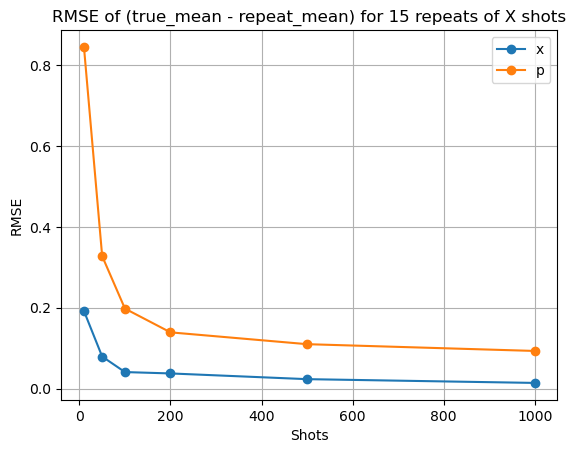

In [ ]:
import strawberryfields as sf
from strawberryfields.ops import Dgate, Sgate, BSgate, MeasureX, MeasureP
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import ipywidgets as widgets

sf.hbar = 1

def shot_quality(alpha, r, shots, repeats):
    each_shot_x_rmse = []
    each_shot_p_rmse = []

    for num_shots in shots:
        ############################################
        # LEFT: analytic Gaussian (no measurements)
        ############################################
        
        eng = sf.Engine("gaussian")
        prog = sf.Program(2)

        with prog.context as q:
            Dgate(alpha,0) | q[0]
            Sgate(r) | q[0]
            BSgate(np.pi/4) | (q[0], q[1])

        state = eng.run(prog).state

        true_means = state.means()[[0,3]] # x0, p1

        ############################################
        # RIGHT: shot-based sampling (post-BS only)
        ############################################
        x_square_error = []
        p_square_error = []

        for _ in range(repeats):    # For each repeat, we do the X-shot measurement, store its mean, calc mean_diff
            x0_samples = []
            p1_samples = []
            for _ in range(num_shots):
                eng = sf.Engine("gaussian")
                prog = sf.Program(2)

                with prog.context as q:
                    Dgate(alpha,0) | q[0]
                    Sgate(r) | q[0]
                    BSgate(np.pi/4) | (q[0], q[1])
                    MeasureX | q[0]
                    MeasureP | q[1]

                result = eng.run(prog)
                samples = result.samples[0]

                x0_samples.append(samples[0])
                p1_samples.append(samples[1])

            ############################################
            # Reconstruct pre-BS parameters from samples
            ############################################
            x0 = np.mean(x0_samples)
            p1 = np.mean(p1_samples)

            diff_to_true_x_mean = true_means[0]-x0
            diff_to_true_p_mean = true_means[1]-p1

            x_square_error.append(diff_to_true_x_mean**2)
            p_square_error.append(diff_to_true_p_mean**2)
        
        each_shot_x_rmse.append(np.sqrt(np.mean(x_square_error)))
        each_shot_p_rmse.append(np.sqrt(np.mean(p_square_error)))

    plt.figure()
    plt.title("RMSE of (true_mean - repeat_mean) for 15 repeats of X shots")
    plt.plot(shots,each_shot_x_rmse,marker="o",label="x")
    plt.plot(shots,each_shot_p_rmse,marker="o", label="p")
    plt.xlabel("Shots")
    plt.ylabel("RMSE")
    plt.legend()
    plt.grid(True)
    plt.show()

shots = [10,50,100,200,500,1000]
#shot_quality(1.5,1.5,shots,15)

#### Covariance Test

In [13]:
import numpy as np
import strawberryfields as sf
from strawberryfields.ops import Dgate, Sgate, BSgate

# Setup engine and program
eng = sf.Engine("gaussian")
prog = sf.Program(3)

with prog.context as q:
    # Qumode 0
    Dgate(1.0, 0) | q[0]
    Sgate(1.0)    | q[0]

    # Qumode 1
    Dgate(0.7, 0) | q[1]
    Sgate(0.7)    | q[1]

    # First beamsplitter between active modes
    BSgate(np.pi/3, 0) | (q[0], q[1])

    # Second beamsplitter with vacuum
    BSgate(np.pi/4)    | (q[1], q[2])

# Run the program
state = eng.run(prog).state

# Function to get reduced Gaussian state (means + cov) for given modes
def reduced_state(state, modes):
    x_idx = modes
    p_idx = [i + state.num_modes for i in modes]
    indices = x_idx + p_idx
    mean = np.concatenate([state.means()[x_idx], state.means()[p_idx]])
    cov  = state.cov()[np.ix_(indices, indices)]
    return mean, cov

# Example: get reduced state for qumodes 1 and 2
modes_to_check = [1,2]
mean_reduced, cov_reduced = reduced_state(state, modes_to_check)

print("All means {x0,x1...p0,p1...}:\n", state.means(),"\n")
print(f"Reduced means (x,p) for modes {modes_to_check}:\n", mean_reduced, "\n")
print(f"Reduced covariance for modes {modes_to_check}:\n", cov_reduced, "\n")

print("There are covariances here...can't use the formula.")

All means {x0,x1...p0,p1...}:
 [-0.23419824  0.69635564  0.69635564  0.          0.          0.        ] 

Reduced means (x,p) for modes [1, 2]:
 [0.69635564 0.69635564 0.         0.        ] 

Reduced covariance for modes [1, 2]:
 [[ 0.58157535 -0.41842465  0.          0.        ]
 [-0.41842465  0.58157535  0.          0.        ]
 [ 0.          0.          3.77779603  2.77779603]
 [ 0.          0.          2.77779603  3.77779603]] 

There are covariances here...can't use the formula.


#### No-BS Heterodyne Method

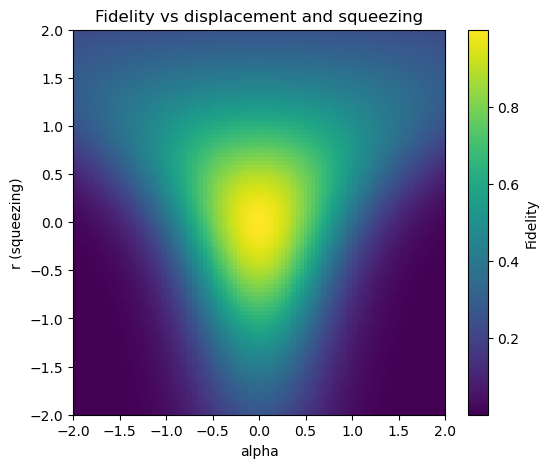

This result is identical to before, where we previously had BS + 2 homodynes!


In [18]:
import numpy as np
import strawberryfields as sf
from strawberryfields.ops import Sgate, MeasureHomodyne, Dgate, BSgate
import matplotlib.pyplot as plt
import tensorflow as tf
import ipywidgets as widgets

sf.hbar = 1 # more standard!
def overlap_map(alpha_range, r_range, res=50):
    alphas = np.linspace(*alpha_range, res)
    rs = np.linspace(*r_range, res)

    overlap_grid = np.zeros((res, res))

    for i, a in enumerate(alphas):
        for j, r in enumerate(rs):
            eng = sf.Engine("gaussian")
            prog = sf.Program(1)

            with prog.context as q:
                
                Dgate(a,0) | q[0]
                Sgate(r) | q[0]

            state = eng.run(prog).state
            means = state.means()
            cov = state.cov()

            ############################ Displacement
            x,p = means[0],means[1]

            ############################ Variance/Squeezing
            x_var = cov[0,0]
            p_var = cov[1,1]

            # GPT - Gaussian Fidelity (specific form with one qumode in vacuum state)
            # I have performed the derivation and can confirm this equation is correct (see Joplin)
            F = (1 / np.sqrt((x_var + 0.5)*(p_var + 0.5))) \
                * np.exp(-0.5 * (
                    (x**2 / (x_var + 0.5)) +
                    (p**2 / (p_var + 0.5))
                ))
            overlap_grid[j,i] = F

    # --- Plot ---
    plt.figure(figsize=(6,5))
    plt.imshow(
        overlap_grid,
        extent=[alphas[0], alphas[-1], rs[0], rs[-1]],
        origin='lower',
        aspect='auto'
    )
    plt.colorbar(label="Fidelity")
    plt.xlabel("alpha")
    plt.ylabel("r (squeezing)")
    plt.title("Fidelity vs displacement and squeezing")
    plt.show()

overlap_map((-2,2), (-2,2), res=100)
print("This result is identical to before, where we previously had BS + 2 homodynes!")

In [23]:
sf.hbar = 1 # more standard!
def two_mode_pre_post_bs(alpha, r):

    fig, ax = plt.subplots(1,1,figsize=(5, 5))
    
    eng = sf.Engine("gaussian")
    prog = sf.Program(1)

    with prog.context as q:
        
        Dgate(alpha,0) | q[0]
        Sgate(r) | q[0]       

    state = eng.run(prog).state

    means = state.means()
    cov = state.cov()

    ############################ Displacement
    x,p = means[0],means[1]

    ############################ Variance/Squeezing
    x_var = cov[0,0]
    p_var = cov[1,1]

    F = (1 / np.sqrt((x_var + 0.5)*(p_var + 0.5))) \
                * np.exp(-0.5 * (
                    (x**2 / (x_var + 0.5)) +
                    (p**2 / (p_var + 0.5))
                ))
    
    from matplotlib.patches import Ellipse

        
    vals, vecs = np.linalg.eigh(cov)
    angle = np.degrees(np.arctan2(*vecs[:,0][::-1]))
    width, height = 2*np.sqrt(vals)

    ellipse = Ellipse(
        xy=means, width=width, height=height, angle=angle,
        edgecolor="red", facecolor='none', lw=2
    )
    ax.add_patch(ellipse)
    ax.plot(x, p, 'o', color="blue")

    ax.set_xlim(-5,5)
    ax.set_ylim(-5,5)
    ax.set_xlabel('x')
    ax.set_ylabel('p')
    ax.set_title("Plot")
    ax.grid(True)

    print(f"Overlap = {F}")

    plt.tight_layout()
    plt.show()

widgets.interact(two_mode_pre_post_bs, alpha=(-2,2,0.1), r=(-2,2,0.05))

interactive(children=(FloatSlider(value=0.0, description='alpha', max=2.0, min=-2.0), FloatSlider(value=0.0, d…

<function __main__.two_mode_pre_post_bs(alpha, r)>

#### Shot-based Version (Heterodyne)

In [9]:
import strawberryfields as sf
from strawberryfields.ops import Dgate, Sgate, BSgate, MeasureX, MeasureP, MeasureHD
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import ipywidgets as widgets

sf.hbar = 1

def two_mode_pre_post_bs(alpha, r, shots):

    ############################################
    # LEFT: analytic Gaussian (no measurements)
    ############################################
    fig, ax = plt.subplots(1,1,figsize=(5, 5))

    eng = sf.Engine("gaussian")
    prog = sf.Program(1)

    with prog.context as q:
        
        Dgate(alpha,0) | q[0]
        Sgate(r) | q[0]       

    state = eng.run(prog).state

    means = state.means()
    cov = state.cov()

    ############################ Displacement
    x,p = means[0],means[1]

    ############################ Variance/Squeezing
    x_var = cov[0,0]
    p_var = cov[1,1]

    F1 = (1 / np.sqrt((x_var + 0.5)*(p_var + 0.5))) \
                * np.exp(-0.5 * (
                    (x**2 / (x_var + 0.5)) +
                    (p**2 / (p_var + 0.5))
                ))
    
    from matplotlib.patches import Ellipse

    vals, vecs = np.linalg.eigh(cov)
    angle = np.degrees(np.arctan2(*vecs[:,0][::-1]))
    width, height = 2*np.sqrt(vals)

    ellipse = Ellipse(
        xy=means, width=width, height=height, angle=angle,
        edgecolor="red", facecolor='none', lw=2
    )
    ax.add_patch(ellipse)
    ax.plot(x, p, 'o', color="blue")

    ax.set_xlim(-5,5)
    ax.set_ylim(-5,5)
    ax.set_xlabel('x')
    ax.set_ylabel('p')
    ax.set_title("Plot")
    ax.grid(True)

    print("ANALYTIC")
    print("Mean x:", x, "Mean p:", p)
    print("Var x:", x_var, "Var p:", p_var)
    print("Fidelity:", F1)

    ############################################
    # RIGHT: shot-based sampling (post-BS only)
    # Note: Heterodyne adds vacuum noise of 1/2 per quadrature, so rescaling of displacement/variance is necessary
    ############################################
    x_samples = []
    p_samples = []

    for _ in range(shots):
        eng = sf.Engine("gaussian")
        prog = sf.Program(1)

        with prog.context as q:
            
            Dgate(alpha,0) | q[0]
            Sgate(r) | q[0]   
            MeasureHD | q[0]    

        result = eng.run(prog)
        z = result.samples[0,0]  # complex number

        # Scaled Heterodyne Results
        x = np.sqrt(2)*np.real(z)
        p = np.sqrt(2)*np.imag(z)

        x_samples.append(x)
        p_samples.append(p)

    # Mean and Variances
    x = np.mean(x_samples)
    p = np.mean(p_samples)
    x_var = np.var(x_samples) - 0.5
    p_var = np.var(p_samples) - 0.5

    F2 = (1 / np.sqrt((x_var + 0.5)*(p_var + 0.5))) \
                * np.exp(-0.5 * (
                    (x**2 / (x_var + 0.5)) +
                    (p**2 / (p_var + 0.5))
                ))


    ax.plot(x_samples,p_samples,".",alpha=0.3)
    plt.tight_layout()
    plt.show()
    print("SHOTS")
    print("Mean x:", x, "Mean p:", p)
    print("Var x:", x_var, "Var p:", p_var)
    print("Fidelity:", F2)

widgets.interact(
    two_mode_pre_post_bs,
    alpha=(-2,2,0.1),
    r=(-2,2,0.05),
    shots=(10,2000,500),
    continuous_update=False
)

interactive(children=(FloatSlider(value=0.0, description='alpha', max=2.0, min=-2.0), FloatSlider(value=0.0, d…

<function __main__.two_mode_pre_post_bs(alpha, r, shots)>

#### Back we go
Well there is no Heterodyne in TF/Fock backend, so I have to go back to the BS-2-Homodyne method! Both work equally well, as all the code cells above show. It's a shame though, as will be more memory inefficient than the simple single-qumode heterodyne.

Accuracy depends on CUTOFF + SHOTS

In [1]:
import strawberryfields as sf
from strawberryfields.ops import Dgate, Sgate, BSgate, MeasureHomodyne
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import ipywidgets as widgets
import tensorflow as tf
tf.get_logger().setLevel('ERROR')

sf.hbar = 1

def two_mode_pre_post_bs(alpha, r, shots, cutoff_dim):
    fig, axes = plt.subplots(1, 2, figsize=(12,6))

    ############################################
    # LEFT: analytic Gaussian (no measurements)
    ############################################
    for ax, bs, title in zip(
        axes,
        [0, np.pi/4],
        ["Pre-BS", "Post-BS"]
    ):
        eng = sf.Engine("gaussian")
        prog = sf.Program(2)

        with prog.context as q:
            Dgate(alpha,0) | q[0]
            Sgate(r) | q[0]
            BSgate(bs) | (q[0], q[1])

        state = eng.run(prog).state

        means0 = state.means()[[0,2]]
        cov0   = state.cov()[np.ix_([0,2],[0,2])]
        means1 = state.means()[[1,3]]
        cov1   = state.cov()[np.ix_([1,3],[1,3])]
        
        for means, cov, color in zip(
            [means0, means1],
            [cov0, cov1],
            ['blue','red']
        ):
            vals, vecs = np.linalg.eigh(cov)
            angle = np.degrees(np.arctan2(*vecs[:,0][::-1]))
            width, height = 2*np.sqrt(vals)

            ellipse = Ellipse(
                xy=means, width=width, height=height,
                angle=angle, edgecolor=color,
                facecolor='none', lw=2
            )
            ax.add_patch(ellipse)
            ax.plot(means[0], means[1], 'o', color=color)

        ax.set_xlim(-5,5); ax.set_ylim(-5,5)
        ax.set_xlabel('x'); ax.set_ylabel('p')
        ax.set_title(title); ax.grid(True)

    ############################################
    # RIGHT: shot-based sampling (post-BS only)
    ############################################
    x0_samples = []
    p1_samples = []

    for _ in range(shots):
        eng = sf.Engine("tf", backend_options={"cutoff_dim": cutoff_dim})
        prog = sf.Program(2)

        with prog.context as q:
            Dgate(alpha,0)              | q[0]
            Sgate(r)                    | q[0]
            BSgate(np.pi/4)             | (q[0], q[1])
            MeasureHomodyne(0)          | q[0]
            MeasureHomodyne(np.pi/2)    | q[1]

        result = eng.run(prog)
        samples = result.samples.numpy().real.astype(np.float64)
        x0_samples.append(samples[0,0])
        p1_samples.append(samples[0,1])

    ax = axes[1]
    ax.scatter(x0_samples, p1_samples, s=5, alpha=0.3)
    
    ############################################
    # Reconstruct pre-BS parameters from samples
    ############################################
    x0 = np.mean(x0_samples)
    p1 = np.mean(p1_samples)

    x0_var = np.var(x0_samples)
    p1_var = np.var(p1_samples)

    # undo BS (both same state after as one is vacuum)
    pre_x = x0*np.sqrt(2)
    pre_p = p1*np.sqrt(2)

    pre_x_var = 2*x0_var - 0.5
    pre_p_var = 2*p1_var - 0.5

    ax.plot(x0,p1,marker="X",color="black")

    # Compute overlap based on computed pre-BS position
    F = (1 / np.sqrt((pre_x_var + 0.5)*(pre_p_var + 0.5))) \
                * np.exp(-0.5 * (
                    (pre_x**2 / (pre_x_var + 0.5)) +
                    (pre_p**2 / (pre_p_var + 0.5))
                ))
    overlap = F
    ############################################
    # Print diagnostics
    ############################################

    print("\nFINAL STATE (shot sampled):")
    print(f"x0 ≈ {x0:.3f}, p1 ≈ {p1:.3f}")
    print(f"x0_var ≈ {x0_var:.3f}, p1_var ≈ {p1_var:.3f}")

    print("\nPRE-BS STATE (shot reconstructed):")
    print(f"x ≈ {pre_x:.3f}, p ≈ {pre_p:.3f}")
    print(f"x_var ≈ {pre_x_var:.3f}, p_var ≈ {pre_p_var:.3f}")

    print("\nMETRICS:")
    print(f"overlap     = {overlap:.4f}")

    plt.tight_layout()
    plt.show()


widgets.interact(
    two_mode_pre_post_bs,
    alpha=(-2,2,0.1),
    r=(-2,2,0.05),
    shots=(10,200,50),
    cutoff_dim=(2,14,2),
    continuous_update=False
)

/home/hep/lgc124/conda_envs/AutoQMLEnv/lib/python3.10/site-packages/strawberryfields/apps/data/sample.py:20: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
2026-03-30 11:34:37.577831: I tensorflow/core/util/port.cc:110] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-03-30 11:34:37.581005: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-03-30 11:34:37.644418: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-03-30 11:34:37.646056: I tensorflow/core/platform/cpu_f

interactive(children=(FloatSlider(value=0.0, description='alpha', max=2.0, min=-2.0), FloatSlider(value=0.0, d…

<function __main__.two_mode_pre_post_bs(alpha, r, shots, cutoff_dim)>

#### Expectation-based, Fock-backend, dual-homodyne method
This ends up not working at all really, reconstructing the variance pre-BS leads to basically negative losses when used in training. For some reason var_x * var_p goes below 0.25? (violating HUP).

I think it is fundamentally because I am doing 2 homodynes on the "same" state, which cannot be done. Actually, the measurements can be, but I can't then invert back to the pre-BS state...as there are correlations I am ignoring!

In [15]:
import numpy as np
import strawberryfields as sf
from strawberryfields.ops import Sgate, MeasureHomodyne, Dgate, BSgate
import matplotlib.pyplot as plt
import tensorflow as tf
import ipywidgets as widgets

sf.hbar = 1 # more standard!
def fid_practice():

    eng = sf.Engine("tf", backend_options={"cutoff_dim": 10})
    prog = sf.Program(2)

    with prog.context as q:
        
        Dgate(0.01,0) | q[0]
        Sgate(2) | q[0]
                    
        BSgate(np.pi/4) | (q[0], q[1])

    state = eng.run(prog).state
            
    trash_modes = [0]
    vacuum_modes = [1]
    fidelity_pairs = tf.Variable(tf.zeros((len(trash_modes),4), dtype=tf.float32))  # will hold (x,x_var,p,p_var) per mode-pair

    # x homodyne on trash
    for idx, mode in enumerate(trash_modes):
        print("IDX,Mode", idx,mode)
        mean_x, var_x = state.quad_expectation(mode)
        print("Mean_x,var_x", mean_x,var_x)
        fidelity_pairs[idx,0].assign(mean_x)
        fidelity_pairs[idx,1].assign(var_x)

    # p homodyne on vacuum
    for idx, mode in enumerate(vacuum_modes):
        print("IDX,Mode", idx,mode)
        mean_p, var_p = state.quad_expectation(mode, phi=np.pi/2)
        print("Mean_p,var_p", mean_p,var_p, "\n")
        fidelity_pairs[idx,2].assign(mean_p)
        fidelity_pairs[idx,3].assign(var_p)

    # Means (multiply by sqrt(2))
    fidelity_pairs[:, 0].assign(fidelity_pairs[:, 0] * tf.sqrt(2.0))
    fidelity_pairs[:, 2].assign(fidelity_pairs[:, 2] * tf.sqrt(2.0))
    # Variances (2 * v - 0.5)
    fidelity_pairs[:, 1].assign(2 * fidelity_pairs[:, 1] - 0.5)
    fidelity_pairs[:, 3].assign(2 * fidelity_pairs[:, 3] - 0.5)

    # Compute overlap based on computed pre-BS position
    pre_x     = fidelity_pairs[:, 0]
    pre_x_var = fidelity_pairs[:, 1]
    pre_p     = fidelity_pairs[:, 2]
    pre_p_var = fidelity_pairs[:, 3]

    print("pre-BS x,var,p,var",fidelity_pairs, "\n")

    fidelities = (1 / tf.sqrt((pre_x_var + 0.5)*(pre_p_var + 0.5))) \
                * tf.exp(-0.5 * (
                    (pre_x**2 / (pre_x_var + 0.5)) + 
                    (pre_p**2 / (pre_p_var + 0.5))))
    print("Fid",fidelities, "\n")
    overall_fidelity = tf.reduce_mean(fidelities)
    print("Ov Fid",overall_fidelity, "\n")
    loss = 1.0 - overall_fidelity
    print("Loss",loss,"\n")

fid_practice()
                    

IDX,Mode 0 0
Mean_x,var_x tf.Tensor(0.0014435751, shape=(), dtype=float32) tf.Tensor(0.27155662, shape=(), dtype=float32)
IDX,Mode 0 1
Mean_p,var_p tf.Tensor(-6.739874e-11, shape=(), dtype=float32) tf.Tensor(1.7498963, shape=(), dtype=float32) 

pre-BS x,var,p,var <tf.Variable 'Variable:0' shape=(1, 4) dtype=float32, numpy=
array([[ 2.0415236e-03,  4.3113232e-02, -9.5316206e-11,  2.9997926e+00]],
      dtype=float32)> 

Fid tf.Tensor([0.725324], shape=(1,), dtype=float32) 

Ov Fid tf.Tensor(0.725324, shape=(), dtype=float32) 

Loss tf.Tensor(0.27467602, shape=(), dtype=float32) 



#### Gaussian-Backend, Differentiable, Multi-QNode Heterodyne

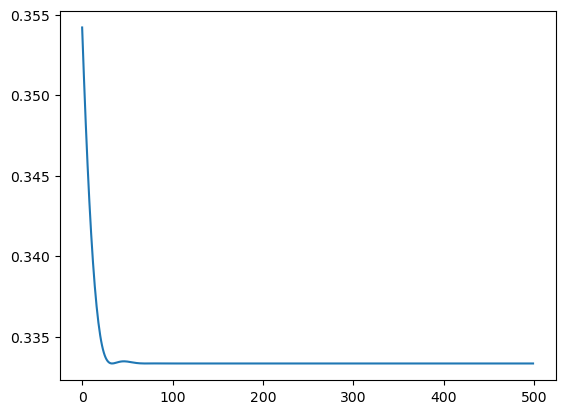

In [32]:
import pennylane as qml
import numpy as np
import torch
import matplotlib.pyplot as plt

dev = qml.device("default.gaussian", wires=3)

@qml.qnode(dev, interface="torch")
def circ_means(params):
    #--Interferometer--------------------------------------
    qml.Beamsplitter(theta=params[0],phi=params[1],wires = (0,1))

    # ------ Squeezing layer (bottleneck) ------ #
    qml.Squeezing(r=params[2], phi=params[3],wires=0)
    qml.Squeezing(r=params[4], phi=params[5],wires=1)

    qml.Beamsplitter(theta=-np.pi/4, phi=-0.0,wires = (1,2))
    return [qml.expval(qml.X(1)),qml.expval(qml.P(2))]

@qml.qnode(dev, interface="torch")
def circ_vars(params):
    #--Interferometer--------------------------------------
    qml.Beamsplitter(theta=params[0],phi=params[1],wires = (0,1))

    # ------ Squeezing layer (bottleneck) ------ #
    qml.Squeezing(r=params[2], phi=params[3],wires=0)
    qml.Squeezing(r=params[4], phi=params[5],wires=1)

    qml.Beamsplitter(theta=-np.pi/4, phi=-0.0,wires = (1,2))
    return [qml.var(qml.X(1)),qml.var(qml.P(2))]

#fig,ax = qml.draw_mpl(circ_means)(params)


def cost(params):
    """Minimise (⟨n⟩ - target)^2."""
    x1,p2 = circ_means(params)
    varx1,varp2 = circ_vars(params)
    fidelity = (1.0 / torch.sqrt((varx1 + 0.5)*(varp2 + 0.5))) * torch.exp(
                                -0.5 * (
                                    (x1**2) / (varx1 + 0.5) +
                                    (p2**2) / (varp2 + 0.5)
                                ))
    return 1-fidelity

# ── Optimisation ──────────────────────────────────────────────────
params = torch.nn.ParameterList([torch.nn.Parameter(
            torch.normal(0, 0.4, size=())
            ) for _ in range(6)])
opt = torch.optim.Adam(params,lr=0.01)

losses = []
epochs = 500
for step in range(epochs):
    loss = cost(params)
    opt.zero_grad()
    loss.backward()
    opt.step()
    losses.append(loss)
    # print([p.item() for p in params])

plt.plot(range(epochs),[l.item() for l in losses])

#### Single QNode, Analytic, Gaussian, Heterodyne

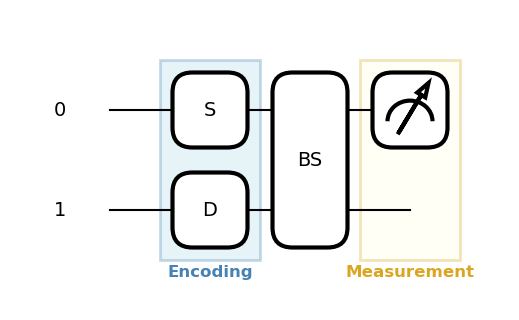

In [18]:
import pennylane as qml
import pennylane.numpy as np
import matplotlib.pyplot as plt

# For N modes, cov is 2N x 2N, means is 2N
# PennyLane quadrature ordering: (x0, x1, ..., p0, p1, ...)

dev = qml.device("default.gaussian", wires=2)

@qml.qnode(dev, diff_method="parameter-shift")
def X(params):
    r, phi, alpha = params
    qml.Squeezing(r, phi, wires=0)
    qml.Displacement(alpha, 0.0, wires=1)
    qml.Beamsplitter(np.pi/4,0,wires=(0,1))
    # First-order moments: <x0>, <p0>, <x1>, <p1>
    return qml.expval(qml.X(0))

params = [1,1,1]
fig,ax = qml.draw_mpl(X)(params)

####################################


# Usage
add_section_box(ax, x_start=-0.5, width=1.0, n_wires=2,
                label="Encoding", facecolor='lightblue', edgecolor='steelblue')

add_section_box(ax, x_start=1.5, width=1, n_wires=2,
                label="Measurement", facecolor='lightyellow', edgecolor='goldenrod')

#### Heatmap HetFid

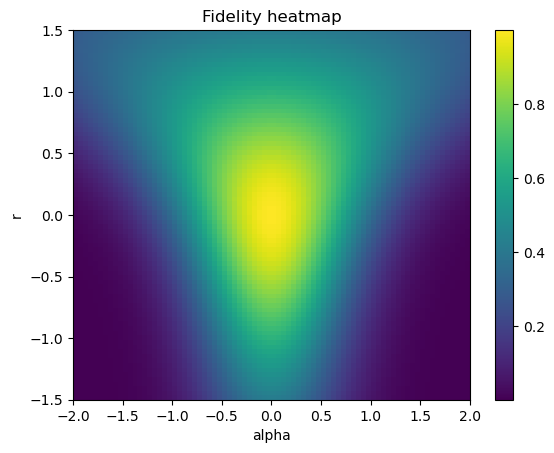

In [24]:
import pennylane as qml
import torch
import numpy as np
import matplotlib.pyplot as plt

# --- devices ---
dev = qml.device('default.gaussian', wires=1)

# --- QNodes (unchanged logic, single device is fine) ---
@qml.qnode(dev, interface="torch")
def circ_mx(params):
    r, phi, alpha = params
    qml.Displacement(alpha, 0.0, wires=0)
    qml.Squeezing(r, phi, wires=0)
    return qml.expval(qml.QuadX(0))

@qml.qnode(dev, interface="torch")
def circ_mp(params):
    r, phi, alpha = params
    qml.Displacement(alpha, 0.0, wires=0)
    qml.Squeezing(r, phi, wires=0)
    return qml.expval(qml.QuadP(0))

@qml.qnode(dev, interface="torch")
def circ_vx(params):
    r, phi, alpha = params
    qml.Displacement(alpha, 0.0, wires=0)
    qml.Squeezing(r, phi, wires=0)
    return qml.var(qml.QuadX(0))

@qml.qnode(dev, interface="torch")
def circ_vp(params):
    r, phi, alpha = params
    qml.Displacement(alpha, 0.0, wires=0)
    qml.Squeezing(r, phi, wires=0)
    return qml.var(qml.QuadP(0))

@qml.qnode(dev, interface="torch")
def circ_45(params):
    r, phi, alpha = params
    qml.Displacement(alpha, 0.0, wires=0)
    qml.Squeezing(r, phi, wires=0)
    qml.Rotation(np.pi/4, wires=0)
    return qml.var(qml.QuadX(0))


# --- fidelity function (single mode) ---
def compute_F(params):
    mx = circ_mx(params) / torch.sqrt(torch.tensor(2.0))
    mp = circ_mp(params) / torch.sqrt(torch.tensor(2.0))
    vx = circ_vx(params) / 2.0
    vp = circ_vp(params) / 2.0
    v45 = circ_45(params) / 2.0

    cov_xp = v45 - (vx + vp) / 2.0

    sigma = torch.stack([
        torch.stack([vx, cov_xp]),
        torch.stack([cov_xp, vp])
    ])

    alpha_vec = torch.stack([mx, mp])

    M = 0.5 * torch.eye(2) + sigma

    det_M = M[0,0]*M[1,1] - M[0,1]*M[1,0]

    M_inv = torch.stack([
        torch.stack([ M[1,1], -M[0,1]]),
        torch.stack([-M[1,0],  M[0,0]])
    ]) / det_M

    quad = alpha_vec @ M_inv @ alpha_vec

    F = torch.exp(-0.5 * quad) / torch.sqrt(det_M)

    return F


# --- grid ---
r_vals = torch.linspace(-1.5, 1.5, 80)
alpha_vals = torch.linspace(-2.0, 2.0, 80)

F_grid = torch.zeros((len(r_vals), len(alpha_vals)))

phi = torch.tensor(0.0)

# --- compute heatmap ---
for i, r in enumerate(r_vals):
    for j, alpha in enumerate(alpha_vals):
        params = torch.stack([r, phi, alpha])
        F_grid[i, j] = compute_F(params)


# --- plot ---
plt.figure()
plt.imshow(F_grid.detach().numpy(),
           origin='lower',
           aspect='auto',
           extent=[alpha_vals.min(), alpha_vals.max(),
                   r_vals.min(), r_vals.max()])

plt.xlabel("alpha")
plt.ylabel("r")
plt.title("Fidelity heatmap")
plt.colorbar()
plt.show()

In [1]:
import pennylane as qml
import numpy as np

dev = qml.device("default.gaussian", wires=1)

@qml.qnode(dev)
def test():
    qml.Displacement(1.0, 0.0, wires=0)  # alpha = 1 (real)
    return qml.expval(qml.QuadX(0))

print(test())  # 2.0 => x = a + a†, sqrt(2) => x = (a+a†)/sqrt(2)

2.0
